# Example 1.8 — Comparison of μ(θ₂) for Four Four-Bar Mechanisms

**Four Bar Mechanisms — Design with Genetic Algorithms and Neural Networks**

Open this notebook in Google Colab: [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/usuario/repo/blob/main/ex1_8_comparacion_mu_cuatro_mecanismos.ipynb)

In [1]:
from numpy import *

def transmission_angle(a, b, c, d, n=720):
    th2 = linspace(0, 2*pi, n, endpoint=False)
    e2  = a**2 + d**2 - 2*a*d*cos(th2)
    cmu = clip((b**2 + c**2 - e2) / (2*b*c), -1., 1.)
    return degrees(arccos(cmu))

mechanisms = [
    ("Reference     ", 50.,  120.,  80., 100.),
    ("Critical zone ", 90.,   60.,  80., 100.),
    ("100% min.     ", 40.,   80.,  75., 100.),
    ("100% robust   ", 188.5, 145.3, 122.6, 37.5),
]

print(f"{'Mechanism':<16} {'μ_min':>6} {'μ_max':>6} {'Opt. zone':>10} {'Δ90°':>6}")
print("-" * 52)
for name, a, b, c, d in mechanisms:
    mu   = transmission_angle(a, b, c, d)
    pct  = 100. * mean((mu >= 45.) & (mu <= 135.))
    dev  = mean(abs(mu - 90.))
    print(f"{name:<16} {mu.min():>5.1f}°  {mu.max():>5.1f}°  {pct:>8.1f}%  {dev:>5.1f}°")

Mechanism         μ_min  μ_max  Opt. zone   Δ90°
----------------------------------------------------
Reference         17.6°   95.1°      67.6%   30.3°
Critical zone      0.0°  180.0°      28.6%   65.6°
100% min.         45.4°  129.1°     100.0%   25.8°
100% robust       68.0°  114.8°     100.0%   14.8°


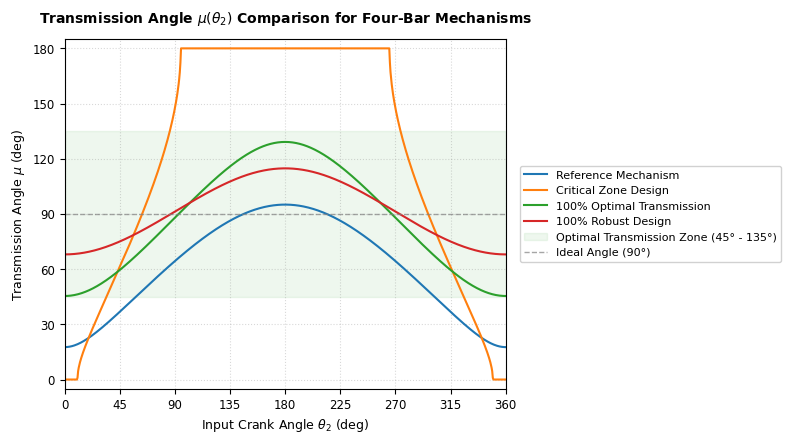

In [4]:
import os
import glob
import matplotlib.pyplot as plt

# 1. Configurar nombre automático del archivo según pautas
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "fig_1_8_mu_comparison_four_mechanisms"
except Exception:
    notebook_name = "fig_1_8_mu_comparison_four_mechanisms"

# 2. Configuración estética para publicación en Springer
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 8.5

# Rango de th2 para el eje X
th2_deg = linspace(0, 360, 720, endpoint=False)

# Crear la figura con dimensiones controladas para una sola página
fig, ax = plt.subplots(figsize=(8, 4.5))

# Mapear nombres a inglés técnico académico
name_mapping = {
    "Reference     ": "Reference Mechanism",
    "Critical zone ": "Critical Zone Design",
    "100% min.     ": "100% Optimal Transmission",
    "100% robust   ": "100% Robust Design"
}

# Graficar la curva de cada mecanismo con etiquetas traducidas
for name, a, b, c, d in mechanisms:
    mu = transmission_angle(a, b, c, d)
    clean_name = name_mapping.get(name, name.strip())
    ax.plot(th2_deg, mu, label=clean_name, linewidth=1.5)

# Configurar la zona óptima de transmisión y la línea ideal de 90°
ax.axhspan(45, 135, color='#2ca02c', alpha=0.08, label='Optimal Transmission Zone (45° - 135°)')
ax.axhline(90, color='gray', linestyle='--', linewidth=1.0, alpha=0.7, label='Ideal Angle (90°)')

# Título y etiquetas en inglés académico según la norma Springer
ax.set_title(r'Transmission Angle $\mu(\theta_2)$ Comparison for Four-Bar Mechanisms', fontsize=10, fontweight='bold', pad=12)
ax.set_xlabel(r'Input Crank Angle $\theta_2$ (deg)', fontsize=9)
ax.set_ylabel(r'Transmission Angle $\mu$ (deg)', fontsize=9)

# Límites y marcas discretas en los ejes
ax.set_xlim(0, 360)
ax.set_ylim(-5, 185)
ax.set_xticks(arange(0, 361, 45))
ax.set_yticks(arange(0, 181, 30))

# Cuadrícula discreta y limpia
ax.grid(True, linestyle=':', color='gray', alpha=0.3)

# Posicionamiento de leyenda para evitar traslapes con los datos
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True, framealpha=0.9, fontsize=8)

plt.tight_layout()

# Exportación doble requerida por la editorial
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()